In [40]:
import tensorflow as tf
import numpy as np
import os
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input

# Path to your dataset
DATASET_PATH = "/Users/prekshyajoshi/instacart_recommender_project/zepto_cnn_dataset_final"

# weights = imagenet means load pretrained MobileNetV2 
# include_top=False → removes the final classification layer i.e. the output layer like "dog","cat" etc
model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg')   

IMG_SIZE = (160, 160)
BATCH_SIZE = 32 

In [41]:
#preprocessing 

def preprocess_image(path):
    # Load image from disk
    img = tf.keras.preprocessing.image.load_img(path)
    
    # Convert to RGB (ensures consistency: 3 channels)
    img = img.convert("RGB")
    
    # Resize image in ram only so og is unchanged
    img = img.resize(IMG_SIZE)
    
    # Convert image to numpy array
    img = tf.keras.preprocessing.image.img_to_array(img)
    
    img = preprocess_input(img)
    
    return img



In [42]:
# Collect all image file paths from dataset 
image_paths = []

for root, dirs, files in os.walk(DATASET_PATH):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg','.png')):
            image_paths.append(os.path.join(root, file))

print("Total images:", len(image_paths))



Total images: 117949


In [43]:
# List to store embeddings
embeddings = []

for i in range(0, len(image_paths), BATCH_SIZE):
    batch_paths = image_paths[i:i+BATCH_SIZE]  # eg: if i = 0 → paths[0:32] or if  i = 32 → paths[32:64]

    batch_images = [preprocess_image(p) for p in batch_paths]  # preprocess each img in  batch
    batch_images = np.array(batch_images)      #convert the list to array so that we can pass it as model's i/p
    
    # Get embeddings for batch
    batch_embeddings = model.predict(batch_images, verbose=0) #pass the batch to model,& verbose is only so it dosnt show progress in o/p
    
    embeddings.append(batch_embeddings)

# Combine all batches in a array
embeddings = np.vstack(embeddings)

print("Embeddings shape:", embeddings.shape)

Embeddings shape: (117949, 1280)


In [44]:
# L2 normalization (imp for cosine similarity otw itll give similarity based on nos and not direction )
norms = np.linalg.norm(embeddings, axis=1, keepdims=True)
norms[norms == 0] = 1  #if embeddings contains all 0 then norm will be 0 so to prevent divison by 0 below we make it 1
embeddings = embeddings / norms

print("Normalized embeddings ready")

Normalized embeddings ready


In [46]:
# Save embeddings and corresponding image paths

np.save("embeddings_final.npy", embeddings)

# Save image paths also
with open("image_paths.txt", "w") as f:
    for path in image_paths:
        f.write(path + "\n")

print("Embeddings and paths saved successfully")

Embeddings and paths saved successfully


In [47]:
print(embeddings.shape)

(117949, 1280)


In [48]:
!pip install faiss-cpu

In [49]:
import faiss
import numpy as np

In [6]:
#RUN THIS IF KERNEL RESTART:

# # Load saved embeddings
# embeddings = np.load("embeddings_final.npy")

# # Load image paths
# with open("image_paths.txt", "r") as f:
#     image_paths = f.read().splitlines()

# print("Embeddings:", embeddings.shape)
# print("Paths:", len(image_paths))

Embeddings: (122168, 1280)
Paths: 122168


In [50]:

d = embeddings.shape[1]

# IndexFlatIP = Inner Product (used for cosine similarity since normalized)
index = faiss.IndexFlatIP(d)  #thisll make an empty container of size d 

# Add embeddings to index
embeddings = embeddings.astype('float32')
index.add(embeddings)   #then well add the actual values to this empty faiss container we made before

print("FAISS index built")

FAISS index built


In [51]:
from collections import defaultdict

k = 5
threshold = 0.99

D, I = index.search(embeddings, k)

# Union-Find for proper cluster detection
parent = list(range(len(image_paths)))

def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x

def union(x, y):
    px, py = find(x), find(y)
    if px != py:
        if px < py:
            parent[py] = px  # keep lower index (the "original")
        else:
            parent[px] = py

# Build duplicate clusters
for i in range(len(I)):
    for j in range(1, k):
        if D[i][j] > threshold and int(I[i][j]) != i:
            union(i, int(I[i][j]))

# From each cluster, keep only the root (lowest index), delete the rest
to_delete = set()
for i in range(len(image_paths)):
    root = find(i)
    if root != i:
        to_delete.add(i)

print(f"Images to delete: {len(to_delete)} / {len(image_paths)}")

#O/P: 14K similar images found

Images to delete: 10423 / 117949


In [52]:
#EXTRA STUFF
import numpy as np

# embeddings: (N, D) numpy array, already normalized if cosine similarity
# FAISS or sklearn output should work

def similarity_stats(embeddings, sample_size=20000):
    idx = np.random.choice(len(embeddings), sample_size, replace=False)
    emb = embeddings[idx]

    # cosine similarity matrix
    sim = emb @ emb.T

    # remove diagonal
    sim = sim[np.triu_indices_from(sim, k=1)]

    print("Max similarity:", np.max(sim))
    print("99th percentile:", np.percentile(sim, 99))
    print("95th percentile:", np.percentile(sim, 95))
    print("Mean similarity:", np.mean(sim))

    return sim

_ = similarity_stats(embeddings)

Max similarity: 0.99985546
99th percentile: 0.7611766457557678
95th percentile: 0.6613224148750305
Mean similarity: 0.4301527


In [35]:
!pip install matplotlib

  Using cached contourpy-1.3.2-cp310-cp310-macosx_11_0_arm64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached pyparsing-3.3.2-py3-none-any.whl.metadata (5.8 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.1/8.1 MB 709.3 kB/s  0:00:11m0:00:0100:01
Using cached contourpy-1.3.2-cp310-cp310-macosx_11_0_arm64.whl (253 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 618.1 kB/s  0:00:04 eta 0:00:01
Using cached pyparsing-3.3.2-py3-none-any.whl (122 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]


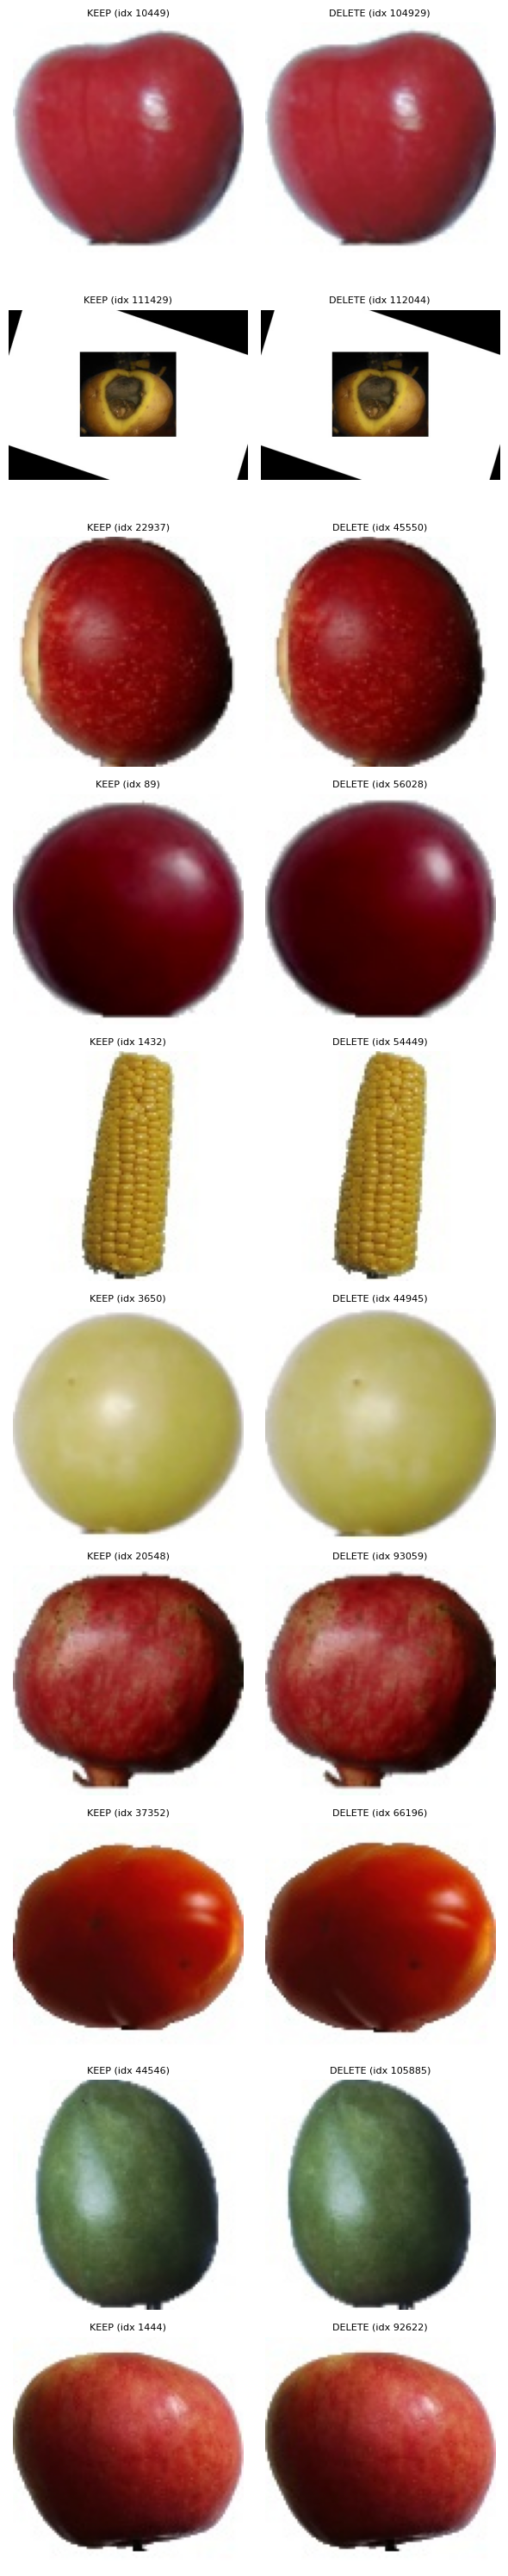

In [53]:
import random
from PIL import Image
import matplotlib.pyplot as plt

# Visually inspect 10 random pairs flagged for deletion
sample_indices = random.sample(list(to_delete), 10)

fig, axes = plt.subplots(10, 2, figsize=(6, 30))
for row, idx in enumerate(sample_indices):
    root = find(idx)  # the "kept" image
    
    img1 = Image.open(image_paths[root])
    img2 = Image.open(image_paths[idx])
    
    axes[row, 0].imshow(img1)
    axes[row, 0].set_title(f"KEEP (idx {root})", fontsize=8)
    axes[row, 0].axis('off')
    
    axes[row, 1].imshow(img2)
    axes[row, 1].set_title(f"DELETE (idx {idx})", fontsize=8)
    axes[row, 1].axis('off')

plt.tight_layout()
plt.savefig("duplicate_check.png", dpi=80)
plt.show()

In [54]:
import os

for idx in to_delete:
    try:
        os.remove(image_paths[idx])
    except:
        pass

print("Deletion complete")

Deletion complete
